In [6]:
import numpy as np
import pandas as pd
import os
from glob import glob
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import chain
from skimage import io

EDA is open-ended, and it is up to you to decide how to look at different ways to slice and dice your data. A good starting point is to look at the requirements for the FDA documentation in the final part of this project to guide (some) of the analyses you do. 

This EDA should also help to inform you of how pneumonia looks in the wild. E.g. what other types of diseases it's commonly found with, how often it is found, what ages it affects, etc. 

Note that this NIH dataset was not specifically acquired for pneumonia. So, while this is a representation of 'pneumonia in the wild,' the prevalence of pneumonia may be different if you were to take only chest x-rays that were acquired in an ER setting with suspicion of pneumonia. 

Perform the following EDA:
* The patient demographic data such as gender, age, patient position,etc. (as it is available)
* The x-ray views taken (i.e. view position)
* The number of cases including: 
    * number of pneumonia cases,
    * number of non-pneumonia cases
* The distribution of other diseases that are comorbid with pneumonia
* Number of disease per patient 
* Pixel-level assessments of the imaging data for healthy & disease states of interest (e.g. histograms of intensity values) and compare distributions across diseases.

Note: use full NIH data to perform the first a few EDA items and use `sample_labels.csv` for the pixel-level assassements. 

Also, **describe your findings and how will you set up the model training based on the findings.**

In [7]:
# ---------- Load data ----------
all_xray_df = pd.read_csv('/data/Data_Entry_2017.csv')
print('Full dataset shape:', all_xray_df.shape)

sample_df = pd.read_csv('sample_labels.csv')
print('Sample labels shape:', sample_df.shape)

Full dataset shape: (112120, 12)
Sample labels shape: (5606, 11)


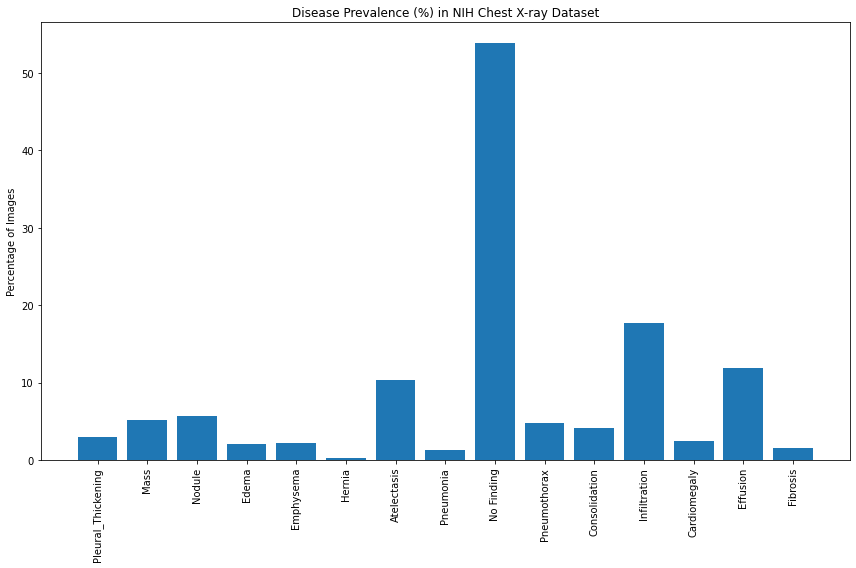

Pneumonia cases: 1430
Non-pneumonia cases: 110674
Pneumonia prevalence: 1.28%


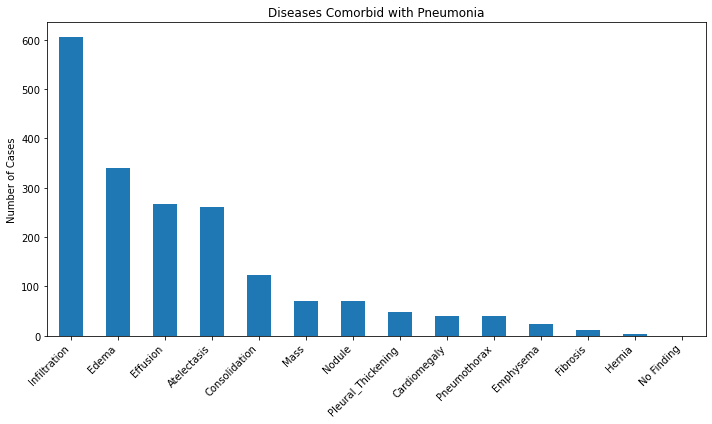

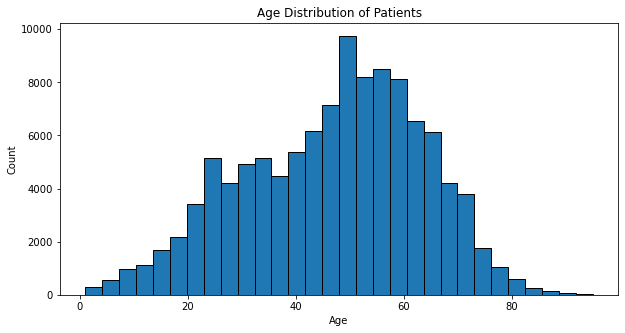

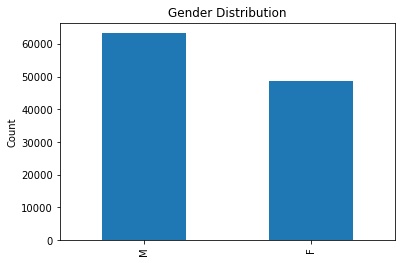

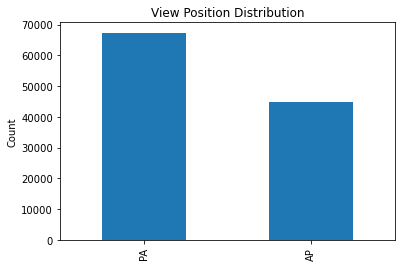

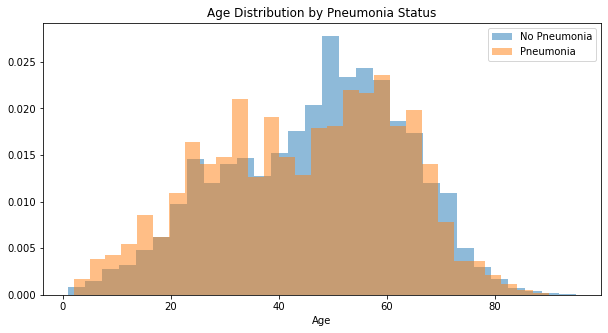

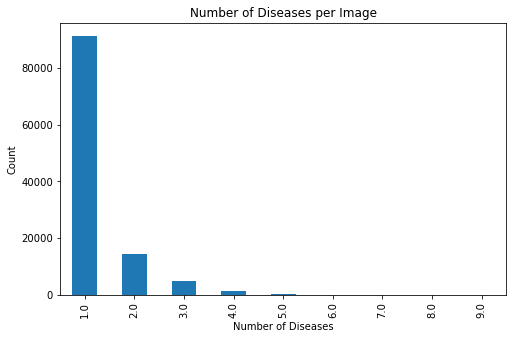

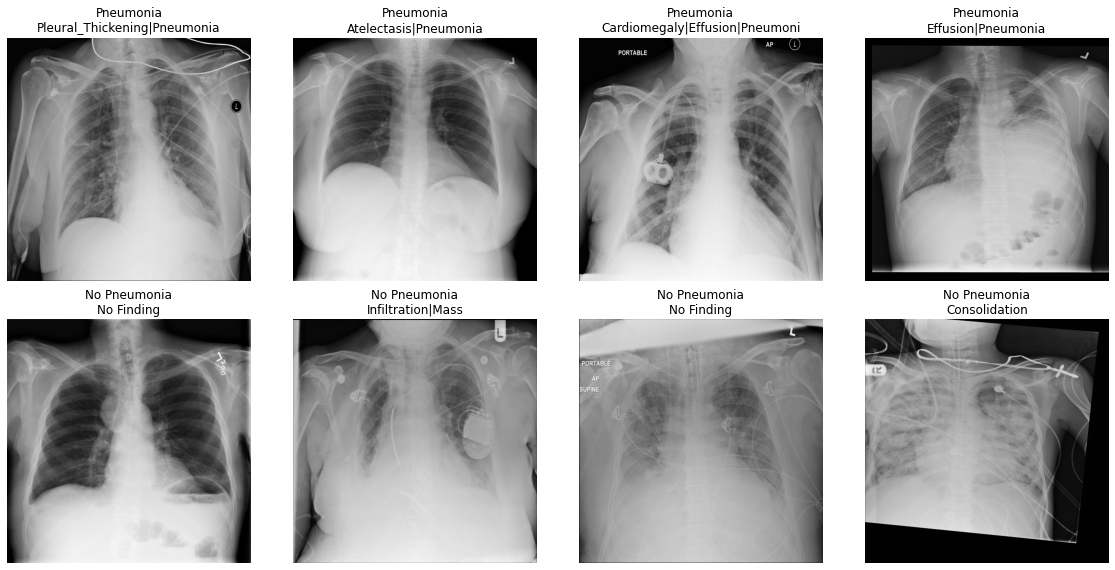

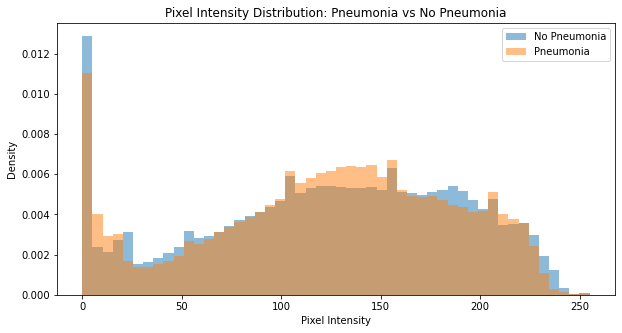

In [8]:
## EDA
# Clean age
all_xray_df['Patient Age'] = all_xray_df['Patient Age'].astype(str).str.replace('Y', '').astype(float)
all_xray_df = all_xray_df[all_xray_df['Patient Age'] < 120]

# ---------- Binary disease columns ----------
all_labels = list(set(chain.from_iterable(
    all_xray_df['Finding Labels'].str.split('|').tolist())))
all_labels = [x for x in all_labels if len(x) > 0]

for c_label in all_labels:
    if len(c_label) > 1:
        all_xray_df[c_label] = all_xray_df['Finding Labels'].map(
            lambda finding: 1.0 if c_label in finding else 0)

# ---------- Disease prevalence ----------
label_counts = 100 * np.mean(all_xray_df[all_labels].values, 0)
fig, ax1 = plt.subplots(1, 1, figsize=(12, 8))
ax1.bar(np.arange(len(label_counts)) + 0.5, label_counts)
ax1.set_xticks(np.arange(len(label_counts)) + 0.5)
ax1.set_xticklabels(all_labels, rotation=90)
ax1.set_title('Disease Prevalence (%) in NIH Chest X-ray Dataset')
ax1.set_ylabel('Percentage of Images')
plt.tight_layout()
plt.show()

# Pneumonia vs non-pneumonia
pneumonia_count = all_xray_df['Pneumonia'].sum()
non_pneumonia_count = len(all_xray_df) - pneumonia_count
print(f'Pneumonia cases: {pneumonia_count:.0f}')
print(f'Non-pneumonia cases: {non_pneumonia_count:.0f}')
print(f'Pneumonia prevalence: {100*pneumonia_count/len(all_xray_df):.2f}%')

# Comorbidities with pneumonia
pneumonia_df = all_xray_df[all_xray_df['Pneumonia'] == 1]
comorbid_labels = [l for l in all_labels if l != 'Pneumonia']
comorbid_counts = pneumonia_df[comorbid_labels].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
comorbid_counts.plot(kind='bar')
plt.title('Diseases Comorbid with Pneumonia')
plt.ylabel('Number of Cases')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ---------- Demographics ----------
# Age
plt.figure(figsize=(10, 5))
plt.hist(all_xray_df['Patient Age'], bins=30, edgecolor='black')
plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

# Gender
plt.figure(figsize=(6, 4))
all_xray_df['Patient Gender'].value_counts().plot(kind='bar')
plt.title('Gender Distribution')
plt.ylabel('Count')
plt.show()

# View Position
plt.figure(figsize=(6, 4))
all_xray_df['View Position'].value_counts().plot(kind='bar')
plt.title('View Position Distribution')
plt.ylabel('Count')
plt.show()

# Age by pneumonia status
plt.figure(figsize=(10, 5))
plt.hist(all_xray_df[all_xray_df['Pneumonia']==0]['Patient Age'],
         bins=30, alpha=0.5, label='No Pneumonia', density=True)
plt.hist(all_xray_df[all_xray_df['Pneumonia']==1]['Patient Age'],
         bins=30, alpha=0.5, label='Pneumonia', density=True)
plt.title('Age Distribution by Pneumonia Status')
plt.xlabel('Age')
plt.legend()
plt.show()

# ---------- Number of diseases per image ----------
all_xray_df['disease_count'] = all_xray_df[all_labels].sum(axis=1)
plt.figure(figsize=(8, 5))
all_xray_df['disease_count'].value_counts().sort_index().plot(kind='bar')
plt.title('Number of Diseases per Image')
plt.xlabel('Number of Diseases')
plt.ylabel('Count')
plt.show()

# ---------- Pixel-level (sample_labels.csv) ----------
all_image_paths = {os.path.basename(x): x for x in
                   glob(os.path.join('/data', 'images*', '*', '*.png'))}
sample_df['path'] = sample_df['Image Index'].map(all_image_paths.get)
sample_df['Pneumonia'] = sample_df['Finding Labels'].apply(
    lambda x: 1 if 'Pneumonia' in x else 0)

# Visualize sample images
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
pneumo_samples = sample_df[sample_df['Pneumonia']==1].sample(4, random_state=42)
normal_samples = sample_df[sample_df['Pneumonia']==0].sample(4, random_state=42)

for idx, (_, row) in enumerate(pneumo_samples.iterrows()):
    if row['path'] and os.path.exists(row['path']):
        img = io.imread(row['path'])
        axes[0, idx].imshow(img, cmap='gray')
        axes[0, idx].set_title(f"Pneumonia\n{row['Finding Labels'][:30]}")
        axes[0, idx].axis('off')

for idx, (_, row) in enumerate(normal_samples.iterrows()):
    if row['path'] and os.path.exists(row['path']):
        img = io.imread(row['path'])
        axes[1, idx].imshow(img, cmap='gray')
        axes[1, idx].set_title(f"No Pneumonia\n{row['Finding Labels'][:30]}")
        axes[1, idx].axis('off')

plt.tight_layout()
plt.show()

# Intensity histograms
def get_intensity_hist(df_subset, n_samples=20):
    intensities = []
    for path in df_subset['path'].dropna().sample(min(n_samples, len(df_subset))):
        if os.path.exists(path):
            img = io.imread(path)
            intensities.extend(img.flatten())
    return np.array(intensities)

pneumo_intensities = get_intensity_hist(sample_df[sample_df['Pneumonia']==1], 30)
normal_intensities = get_intensity_hist(sample_df[sample_df['Pneumonia']==0], 30)

plt.figure(figsize=(10, 5))
plt.hist(normal_intensities, bins=50, alpha=0.5, label='No Pneumonia', density=True)
plt.hist(pneumo_intensities, bins=50, alpha=0.5, label='Pneumonia', density=True)
plt.title('Pixel Intensity Distribution: Pneumonia vs No Pneumonia')
plt.xlabel('Pixel Intensity')
plt.ylabel('Density')
plt.legend()
plt.show()

Findings summary:

Pneumonia is rare (~1–2%). Heavy class imbalance.
Common comorbidities: Infiltration, Atelectasis, Effusion.
Broad age range, both genders, both PA and AP views.
Pixel intensity distributions overlap heavily → spatial features matter.
Training plan: patient-level split, balance training set (~50% positive), realistic validation prevalence (~20%), mild CXR-appropriate augmentation, optimize F1/threshold rather than accuracy.